# Predicting Life Expectancy Across Countries
## DAT 402 · Project 2
**Jonas Shenker**

**Question:** Can economic, healthcare, sanitation, and dietary indicators predict life expectancy in countries excluded from training?

The project will use a random forest, two different types of neural networks, PCA, and k-means to analyze country profiles. The goal is to determine how accurately the indicators can predict longevity for the entire population and where the models are failing. Tests that are done across multiple countries can provide insight into whether a model has identified relationships that are transferable between populations. This information is helpful when assessing the advantages and disadvantages of using economic and service access indicators to predict longevity.



## 1. Dataset

The data comes from **Miguel Roca's Global Health, Nutrition, Mortality, Economic Data**, Version 1 (2025), published on Kaggle under CC BY-NC-SA 4.0:
https://www.kaggle.com/datasets/miguelroca/global-health-nutrition-mortality-economic-data

The compiler uses data from several sources including the World Bank, WHO, UNICEF, Our World in Data, FAOSTAT, and a few other health related databases. This CSV file has 22,050 rows and 150 columns spanning the years 1990 to 2019. Each row represents a location, year, and sex category. The primary variable of interest is life expectancy at birth, which is measured in years. The table below lists the selected variables based on the compiler's dictionary, and the original variable names are used.


In [3]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, silhouette_score
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

SEED = 402
np.random.seed(SEED)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
    'savefig.dpi': 160
})

# Load the CSV from the current working folder.
DATA_PATH = Path("UnifiedDataset.csv")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Place UnifiedDataset.csv in the current working folder "
        "or upload it through the Colab Files sidebar."
    )

raw = pd.read_csv(DATA_PATH)

ARTIFACTS = Path('figures')
ARTIFACTS.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(ARTIFACTS / name, bbox_inches='tight')
    plt.show()

print(f'Raw file: {raw.shape[0]:,} rows × {raw.shape[1]} columns')
print(f'Years: {raw.Year.min()}–{raw.Year.max()}')
print(f'Overall missing-cell fraction: {raw.isna().mean().mean():.1%}')
print(
    f'Duplicate country/year/sex keys: '
    f'{raw.duplicated(["Country", "Year", "Gender"]).sum()}'
)

assert not raw.duplicated(['Country', 'Year', 'Gender']).any()

Raw file: 22,050 rows × 150 columns
Years: 1990–2019
Overall missing-cell fraction: 65.3%
Duplicate country/year/sex keys: 0


In [4]:
dictionary = pd.DataFrame([
    ('Life Expectancy', 'Target', 'Years at birth'),
    ('GDP per Capita', 'Predictor', 'Dollars per person; price basis unspecified'),
    ('Government Expenditure Health', 'Predictor', '% of GDP'),
    ('Basic Drinking Water Services', 'Predictor', '% of population'),
    ('Basic Sanization Services Total', 'Predictor', '% of population'),
    ('Clean Fuel and Technology', 'Predictor', '% of population'),
    ('Doctors', 'Predictor', 'Per 10,000 residents'),
    ('Nurses and Midwifes', 'Predictor', 'Per 10,000 residents'),
    ('Vegetable Consumption', 'Predictor', 'kg/person/year'),
    ('Diet Calories Animal Protein', 'Predictor', 'kcal/person/day'),
    ('Diet Calories Plant Protein', 'Predictor', 'kcal/person/day'),
    ('Diet Calories Fat', 'Predictor', 'kcal/person/day'),
    ('Diet Calories Carbohydrates', 'Predictor', 'kcal/person/day'),
    ('Year', 'Predictor / selection', 'Calendar year'),
    ('Country', 'Grouping only', 'Geographic identifier'),
    ('Gender', 'Selection only', 'Both sexes retained')
], columns=['CSV field', 'Role', 'Compiler-reported unit / meaning'])
display(dictionary.set_index('CSV field'))
print('Original CSV spellings are retained to make field mapping reproducible.')


,Role,Compiler-reported unit / meaning
CSV field,,
Life Expectancy,Target,Years at birth
GDP per Capita,Predictor,Dollars per person; price basis unspecified
Government Expenditure Health,Predictor,% of GDP
Basic Drinking Water Services,Predictor,% of population
Basic Sanization Services Total,Predictor,% of population
Clean Fuel and Technology,Predictor,% of population
Doctors,Predictor,"Per 10,000 residents"
Nurses and Midwifes,Predictor,"Per 10,000 residents"
Vegetable Consumption,Predictor,kg/person/year


Original CSV spellings are retained to make field mapping reproducible.


## 2. Data preparation

I first made a subset of my data by filtering it down to country-level observations for all sexes combined starting from 2000 and onward. I did not include any regional aggregate data. I chose twelve country-level variables that were relevant to economic conditions, health care, access to basic services, and nutrition to be used as predictors. Any negative variable value or percentage over 100 was classified as missing, and none of the variables in this sample were classified as missing using these definitions. Every observation was shown to have at least six non-missing variables, which resulted in 3,016 observations across 195 countries and territories from 2000-2017. This allowed the use of incomplete observations while reducing the need for imputation.


In [5]:
AGGREGATES = ['Africa','Americas','Asia','Europe','Latin America and the Caribbean',
              'Northern America','Oceania','World']
CANDIDATES = ['GDP per Capita','Government Expenditure Health',
    'Basic Drinking Water Services','Basic Sanization Services Total',
    'Clean Fuel and Technology','Doctors','Nurses and Midwifes',
    'Vegetable Consumption','Diet Calories Animal Protein','Diet Calories Plant Protein',
    'Diet Calories Fat','Diet Calories Carbohydrates']
PERCENT_COLUMNS = ['Government Expenditure Health','Basic Drinking Water Services',
                   'Basic Sanization Services Total','Clean Fuel and Technology']
base = raw.loc[(raw.Gender == 'Both sexes') & (raw.Year >= 2000) &
               (~raw.Country.isin(AGGREGATES)),
               ['Country','Year','Life Expectancy'] + CANDIDATES].copy()
invalid_counts = {}
for col in CANDIDATES:
    base[col] = pd.to_numeric(base[col], errors='coerce')
    bad = (base[col] < 0) | (~np.isfinite(base[col]) & base[col].notna())
    if col in PERCENT_COLUMNS:
        bad |= base[col] > 100
    invalid_counts[col] = int(bad.sum())
    base.loc[bad, col] = np.nan
eligible = base[CANDIDATES].notna().sum(axis=1) >= 6
study = base.loc[eligible & base['Life Expectancy'].notna()].reset_index(drop=True)
print(f'Before coverage filter: {len(base):,} rows, {base.Country.nunique()} geographic units')
print(f'After coverage filter: {len(study):,} rows, {study.Country.nunique()} geographic units')
print(f'Rows removed by coverage filter: {(~eligible).sum():,}')
print('Invalid measurements set to missing:', sum(invalid_counts.values()))
display(pd.DataFrame({'Invalid values removed':invalid_counts}))
assert len(study) >= 500
study.to_csv('Project2_Analysis_Data.csv', index=False)
print(f'Retained years: {study.Year.min()}–{study.Year.max()}')
coverage_audit = pd.DataFrame({'Before filter':base.groupby('Year').size(),
                              'After filter':study.groupby('Year').size()}).fillna(0).astype(int)
display(coverage_audit)
coverage_audit.to_csv('Project2_Coverage_Audit.csv')

Before coverage filter: 4,700 rows, 235 geographic units
After coverage filter: 3,016 rows, 195 geographic units
Rows removed by coverage filter: 1,684
Invalid measurements set to missing: 0


,Invalid values removed
GDP per Capita,0
Government Expenditure Health,0
Basic Drinking Water Services,0
Basic Sanization Services Total,0
Clean Fuel and Technology,0
Doctors,0
Nurses and Midwifes,0
Vegetable Consumption,0
Diet Calories Animal Protein,0
Diet Calories Plant Protein,0


Retained years: 2000–2017


,Before filter,After filter
Year,,
2000,235,173
2001,235,171
2002,235,171
2003,235,174
2004,235,182
2005,235,175
2006,235,174
2007,235,174
2008,235,181


### Training, validation, and testing

The countries are split into three groups: training (about 60 percent), validation (about 20 percent) and test (about 20 percent). All of the years for each country will be kept together so we can see how well the models work on countries that have not been included in the model's training. I only use the training data to remove any variables (predictors) with more than 45 percent missing values, then I replace any other missing values with the median value and finally I can standardize all of the input values for our neural networks. All 12 variables meet the missingness requirement. I then converted GDP to its logarithm and added year as an additional variable. I will also use the validation set to choose the best model parameters and we will use the test set to assess the performance of the final models.


In [6]:
split1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
dev_idx, test_idx = next(split1.split(study, groups=study.Country))
dev = study.iloc[dev_idx]
split2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED+1)
train_rel, val_rel = next(split2.split(dev, groups=dev.Country))
train = dev.iloc[train_rel].copy()
val = dev.iloc[val_rel].copy()
test = study.iloc[test_idx].copy()
assert set(train.Country).isdisjoint(val.Country)
assert set(train.Country).isdisjoint(test.Country)
assert set(val.Country).isdisjoint(test.Country)
features = [c for c in CANDIDATES if train[c].isna().mean() <= 0.45]
print('Retained predictors:', features)
display(pd.DataFrame([{'Split':n,'Rows':len(d),'Geographic units':d.Country.nunique()}
                      for n,d in [('Train',train),('Validation',val),('Test',test)]]))
def get_X(frame, cols):
    result = frame[cols].copy()
    if 'GDP per Capita' in result:
        result['GDP per Capita'] = np.log1p(result['GDP per Capita'])
    return result
model_features = features + ['Year']
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(get_X(train, model_features))
X_val = imputer.transform(get_X(val, model_features))
X_test = imputer.transform(get_X(test, model_features))
scaler = StandardScaler()
Xs_train = scaler.fit_transform(X_train)
Xs_val = scaler.transform(X_val)
Xs_test = scaler.transform(X_test)
y_train = train['Life Expectancy'].to_numpy()
y_val = val['Life Expectancy'].to_numpy()
y_test = test['Life Expectancy'].to_numpy()
display(train[features].isna().mean().mul(100).rename('Training missing (%)').round(1).to_frame())

Retained predictors: ['GDP per Capita', 'Government Expenditure Health', 'Basic Drinking Water Services', 'Basic Sanization Services Total', 'Clean Fuel and Technology', 'Doctors', 'Nurses and Midwifes', 'Vegetable Consumption', 'Diet Calories Animal Protein', 'Diet Calories Plant Protein', 'Diet Calories Fat', 'Diet Calories Carbohydrates']


,Split,Rows,Geographic units
0,Train,1845,117
1,Validation,568,39
2,Test,603,39


,Training missing (%)
GDP per Capita,3.7
Government Expenditure Health,15.2
Basic Drinking Water Services,3.4
Basic Sanization Services Total,3.5
Clean Fuel and Technology,6.0
Doctors,38.0
Nurses and Midwifes,36.6
Vegetable Consumption,4.5
Diet Calories Animal Protein,21.9
Diet Calories Plant Protein,21.9


## 3. Exploratory analysis

The following figures show data coverage, training-set life expectancy, and its relationships with GDP and sanitation.


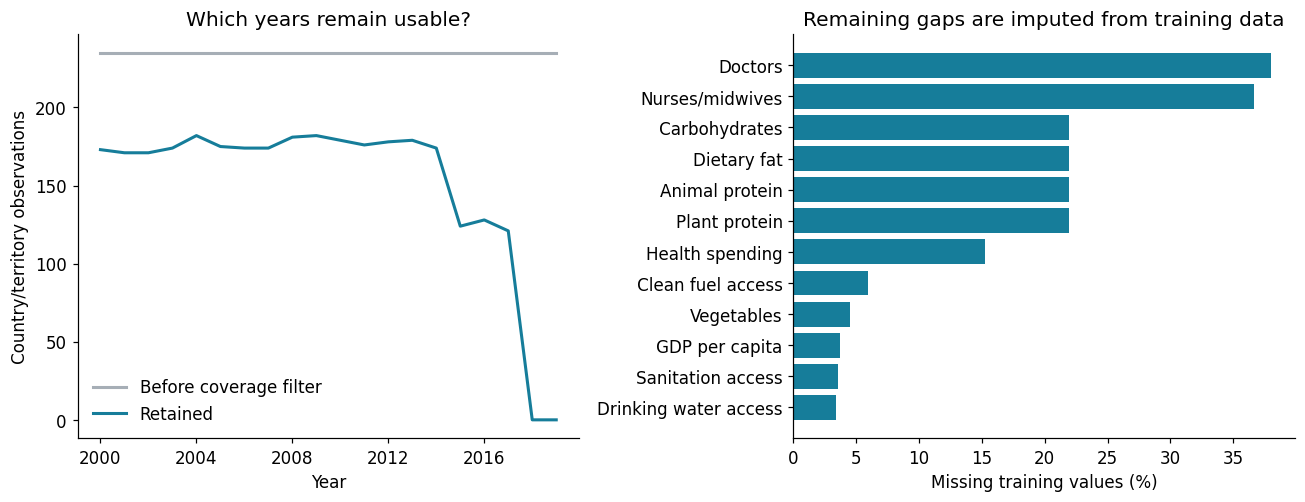

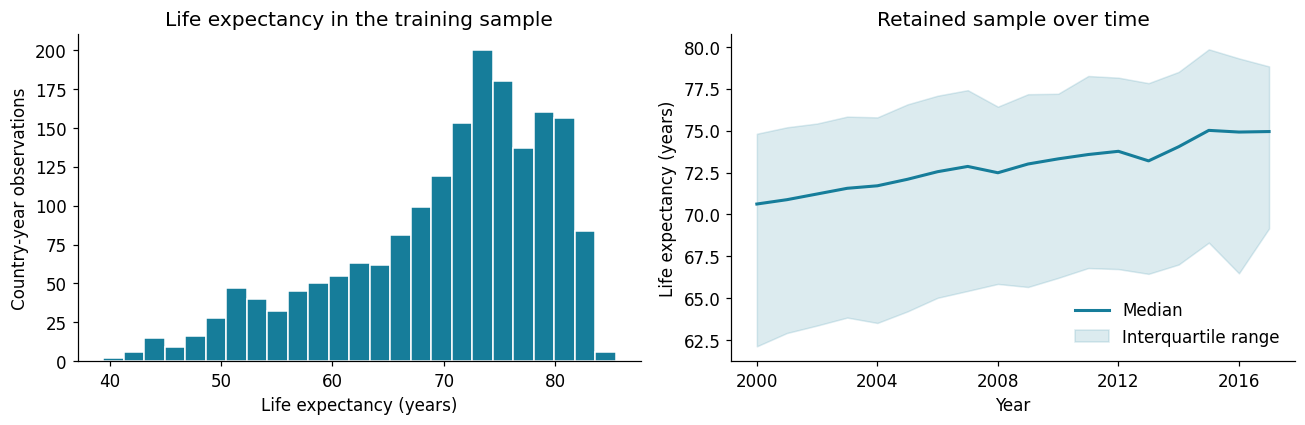

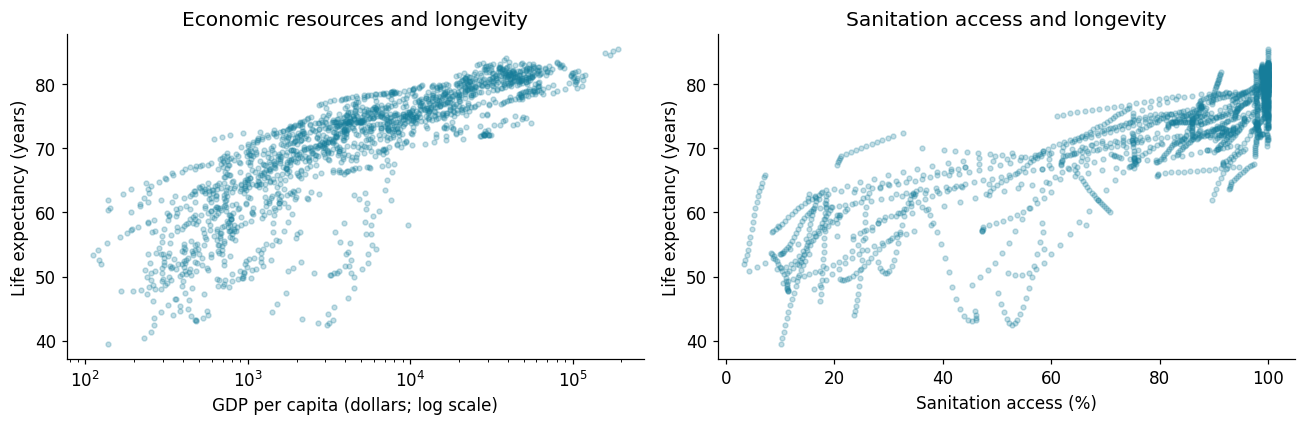

In [7]:
from matplotlib.ticker import MaxNLocator
short_names = {'GDP per Capita':'GDP per capita',
 'Government Expenditure Health':'Health spending',
 'Basic Drinking Water Services':'Drinking water access',
 'Basic Sanization Services Total':'Sanitation access',
 'Clean Fuel and Technology':'Clean fuel access',
 'Doctors':'Doctors', 'Nurses and Midwifes':'Nurses/midwives',
 'Vegetable Consumption':'Vegetables',
 'Diet Calories Animal Protein':'Animal protein',
 'Diet Calories Plant Protein':'Plant protein',
 'Diet Calories Fat':'Dietary fat',
 'Diet Calories Carbohydrates':'Carbohydrates','Year':'Year'}
fig, axes = plt.subplots(1,2,figsize=(12,4.7))
axes[0].plot(coverage_audit.index,coverage_audit['Before filter'],label='Before coverage filter',lw=2,color='#a6aeb6')
axes[0].plot(coverage_audit.index,coverage_audit['After filter'],label='Retained',lw=2,color='#167d9a')
axes[0].set(xlabel='Year',ylabel='Country/territory observations',title='Which years remain usable?')
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True,nbins=6))
axes[0].legend(frameon=False)
miss = train[features].isna().mean().mul(100).sort_values()
axes[1].barh([short_names[c] for c in miss.index],miss,color='#167d9a')
axes[1].set(xlabel='Missing training values (%)',title='Remaining gaps are imputed from training data')
fig.tight_layout()
savefig('00_data_coverage.png')

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(y_train, bins=25, color='#167d9a', edgecolor='white')
axes[0].set(xlabel='Life expectancy (years)', ylabel='Country-year observations',
            title='Life expectancy in the training sample')
annual = train.groupby('Year')['Life Expectancy'].agg(['median', 'count'])
lo = train.groupby('Year')['Life Expectancy'].quantile(.25)
hi = train.groupby('Year')['Life Expectancy'].quantile(.75)
axes[1].plot(annual.index, annual['median'], color='#167d9a', lw=2, label='Median')
axes[1].fill_between(annual.index, lo, hi, color='#167d9a', alpha=.15, label='Interquartile range')
axes[1].set(xlabel='Year', ylabel='Life expectancy (years)', title='Retained sample over time')
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True,nbins=6))
fig.tight_layout()
savefig('01_life_expectancy_distribution.png')

fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, col in zip(axes, ['GDP per Capita','Basic Sanization Services Total']):
    observed = train.dropna(subset=[col])
    ax.scatter(observed[col], observed['Life Expectancy'], s=10, alpha=.25, color='#167d9a')
    ax.set(xlabel=short_names[col] + (' (dollars; log scale)' if col=='GDP per Capita' else ' (%)'), ylabel='Life expectancy (years)')
    if col == 'GDP per Capita':
        ax.set_xscale('log')
        ax.set_title('Economic resources and longevity')
    else:
        ax.set_title('Sanitation access and longevity')
fig.tight_layout()
savefig('02_predictor_associations.png')

### Observations

- Due to the small number of available predictors for 2018-2019, the coverage rule excludes these years. There are many more missing values in staffing variables than there are in water and sanitation.
- In general it shows that as time goes on, life expectancy increases within the remaining training set. Since the country composition might vary, this does not represent a population-weighted global trend.
- Both GDP and sanitation seem to correlate with life expectancy in a non-linear manner. However, neither can fully explain why there is a difference in life expentency between the countries.

Additionally, while there is correlation, it does not imply causation.


## 4. Unsupervised learning: PCA and k-means

I used 107 training countries/territories in 2010 so that every country's profile would be based on the same year. All features had to have at least 70% of the data available. Missing values were replaced with the median value at that time. Before standardizing the predictors, I had to clip values at the 2.5th and 97.5th percentiles so I could reduce the influence of outliers. Outlier removal was only done for clustering. PCA reduced the number of indicators to two for visualization purposes. K-means clustered similar profiles based on all of the standardized features. I evaluated 2 to 6 clusters using silhouette scores to figure out how well separated the clusters were, and I required at least five countries per cluster. Life expectancy was not included in either method but was added later for interpretation.


2010 snapshot: 107 training geographic units
Profile predictors: ['GDP per Capita', 'Government Expenditure Health', 'Basic Drinking Water Services', 'Basic Sanization Services Total', 'Clean Fuel and Technology', 'Doctors', 'Vegetable Consumption', 'Diet Calories Animal Protein', 'Diet Calories Plant Protein', 'Diet Calories Fat', 'Diet Calories Carbohydrates']
Chosen k: 2; silhouette: 0.342
Two PCA components retain 72.9% of variance


,k,Silhouette,Smallest cluster
0,2,0.342261,43
1,3,0.260700,28
2,4,0.296302,18
3,5,0.250407,18
4,6,0.231818,12


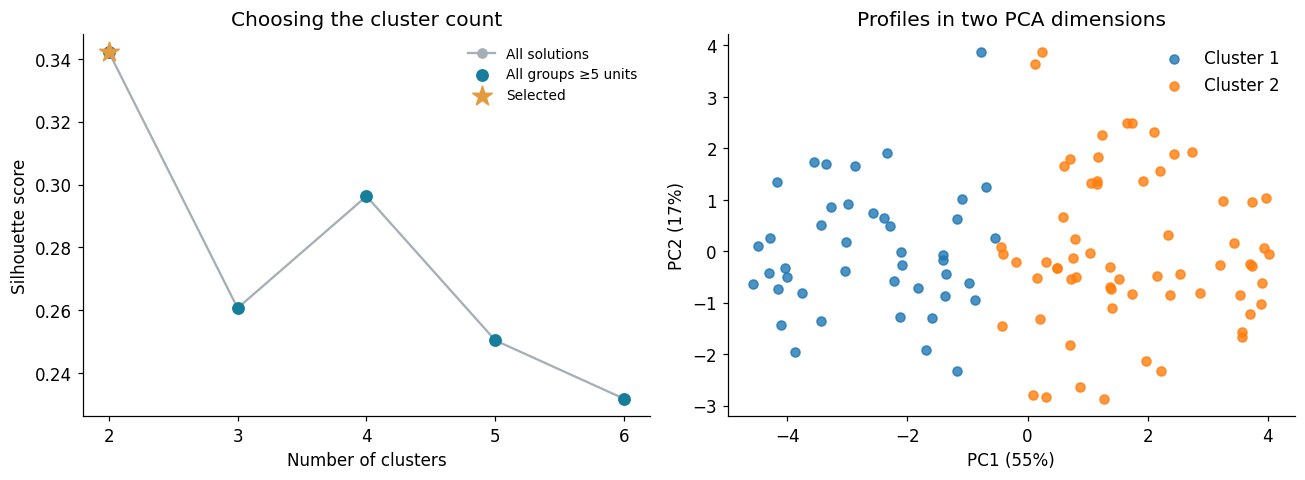

,Units,Median_life_expectancy,Median_GDP,Median_sanitation
Cluster,,,,
1,43,62.53,1299.34,40.96
2,64,75.86,12928.65,95.74


,PC1 loading,PC2 loading
GDP per Capita,0.377,-0.052
Government Expenditure Health,0.259,-0.100
Basic Drinking Water Services,0.353,0.005
Basic Sanization Services Total,0.361,0.036
Clean Fuel and Technology,0.352,0.053
Doctors,0.303,0.086
Vegetable Consumption,0.229,0.423
Diet Calories Animal Protein,0.366,-0.125
Diet Calories Plant Protein,-0.097,0.640
Diet Calories Fat,0.350,-0.083


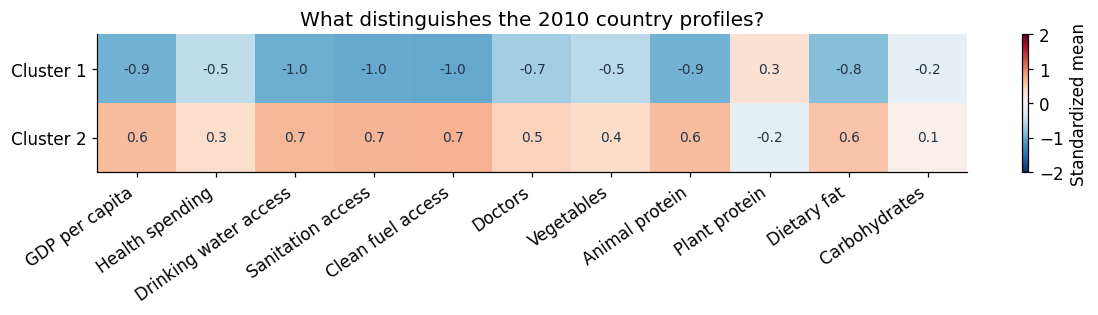

In [8]:
snapshot = train.loc[train.Year == 2010].copy()
profile_features = [c for c in features if snapshot[c].notna().mean() >= .70]
profile_imp = SimpleImputer(strategy='median')
profile_scale = StandardScaler()
profile_values = get_X(snapshot, profile_features)
profile_clipped = profile_values.clip(lower=profile_values.quantile(.025),
                                      upper=profile_values.quantile(.975),axis=1)
Z = profile_scale.fit_transform(profile_imp.fit_transform(profile_clipped))
pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(Z)
cluster_runs = []
with threadpool_limits(limits=1):
    for k in range(2,7):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
        labels = km.fit_predict(Z)
        cluster_runs.append((k, silhouette_score(Z, labels), km))
eligible_cluster_runs = [row for row in cluster_runs
                        if np.bincount(row[2].labels_).min() >= 5]
assert eligible_cluster_runs, 'No cluster solution meets the minimum group size.'
best_k, best_silhouette, cluster_model = max(eligible_cluster_runs, key=lambda row:row[1])
snapshot['Cluster'] = cluster_model.labels_ + 1
print(f'2010 snapshot: {len(snapshot)} training geographic units')
print('Profile predictors:',profile_features)
print(f'Chosen k: {best_k}; silhouette: {best_silhouette:.3f}')
print(f'Two PCA components retain {pca.explained_variance_ratio_.sum():.1%} of variance')
display(pd.DataFrame([(k,s,int(np.bincount(m.labels_).min())) for k,s,m in cluster_runs],
                     columns=['k','Silhouette','Smallest cluster']))
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
axes[0].plot([r[0] for r in cluster_runs], [r[1] for r in cluster_runs], marker='o', color='#a6aeb6',label='All solutions')
axes[0].scatter([r[0] for r in eligible_cluster_runs],[r[1] for r in eligible_cluster_runs],
                color='#167d9a',s=55,label='All groups ≥5 units',zorder=3)
axes[0].scatter([best_k],[best_silhouette],marker='*',s=180,color='#e49b40',label='Selected',zorder=4)
axes[0].set_xticks(range(2,7))
axes[0].legend(frameon=False,fontsize=9)
axes[0].set(xlabel='Number of clusters',ylabel='Silhouette score', title='Choosing the cluster count')
palette = plt.get_cmap('tab10')
for group in range(1,best_k+1):
    mask = snapshot.Cluster.to_numpy() == group
    axes[1].scatter(Z2[mask,0], Z2[mask,1], color=palette(group-1), s=35, alpha=.8,
                    label=f'Cluster {group}')
axes[1].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%})',
            ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%})', title='Profiles in two PCA dimensions')
axes[1].legend(frameon=False)
fig.tight_layout()
savefig('03_pca_clusters.png')
cluster_summary = snapshot.groupby('Cluster').agg(
    Units=('Country','count'), Median_life_expectancy=('Life Expectancy','median'),
    Median_GDP=('GDP per Capita','median'),
    Median_sanitation=('Basic Sanization Services Total','median'))
display(cluster_summary.round(2))
cluster_summary.to_csv('Project2_Cluster_Summary.csv')
loading_table=pd.DataFrame(pca.components_.T,index=profile_features,columns=['PC1 loading','PC2 loading'])
display(loading_table.round(3))
profile_means=pd.DataFrame(Z,columns=profile_features).assign(Cluster=snapshot.Cluster.to_numpy()).groupby('Cluster').mean()
fig,ax=plt.subplots(figsize=(11,max(3,1.0*best_k)))
heat=ax.imshow(profile_means,aspect='auto',cmap='RdBu_r',vmin=-2,vmax=2)
ax.set_xticks(range(len(profile_features)),[short_names[c] for c in profile_features],rotation=35,ha='right')
ax.set_yticks(range(best_k),[f'Cluster {k}' for k in profile_means.index])
for i in range(best_k):
    for j in range(len(profile_features)):
        value=profile_means.iloc[i,j]
        ax.text(j,i,f'{value:.1f}',ha='center',va='center',color='white' if abs(value)>1.1 else '#243445',fontsize=9)
fig.colorbar(heat,ax=ax,label='Standardized mean')
ax.set_title('What distinguishes the 2010 country profiles?')
fig.tight_layout()
savefig('07_cluster_profiles.png')

### Cluster results

The two PCA components explained **72.9 percent of all variance**. Component One is related to economic resources and availability of services, whereas Component Two is related to diet. The best number of clusters is **two**, with a silhouette score of **0.342**, which shows that there are some distinctions between the two clusters. Cluster One has 43 units and their median life expectancy is **62.5 years** and their access to sanitation is **41.0 percent**. Cluster Two has 64 units and their median life expectancy is **75.9 years** and their access to sanitation is **95.7 percent**. The heatmap shows broader differences in the predictors used. These profiles describe the characteristics of each cluster; however, they do not show why those characteristics exist. On the heatmap, positive values represent values greater than the standardized 2010 sample average and negative values represent values less than the standardized 2010 sample average.

## 5. Supervised learning

- **Baseline:** Predict the average life expectancy of the training data.
- **Random Forest:** Use a group of 200 decision trees. Then test two different maximum tree depths (8 vs. no limit here) and require at least four samples in each terminal node.
- **Neural Network:** Evaluate two different neural network architectures (one hidden layer with 32 neurons vs. two hidden layers with 64 and 32 neurons). All other hyperparameters were held constant: rectified linear unit activation functions, Adam optimizer, input/target standardization, and L2 regularization weight of 0.01.

All hyperparameter values were selected to minimize the validation **mean absolute error (MAE)**, measured in years. Each neural network may be trained for up to 500 epochs; however, if there is no significant improvement in the validation set for 35 consecutive epochs, training will cease and the best-performing model's weights will be reloaded.

Additionally, a manual loop is used to ensure that the countries in the validation set remain separate from those in the training set. Learning curves are displayed for all models.


Neural network (32,): best epoch 38, validation MAE 3.758
Neural network (64, 32): best epoch 14, validation MAE 3.400


,Configuration,MAE,RMSE,R2
0,Random forest (depth=8),3.629,4.982,0.694
1,Random forest (depth=None),3.584,4.974,0.695
2,"Neural network (32,)",3.758,4.986,0.693
3,"Neural network (64, 32)",3.400,4.796,0.716


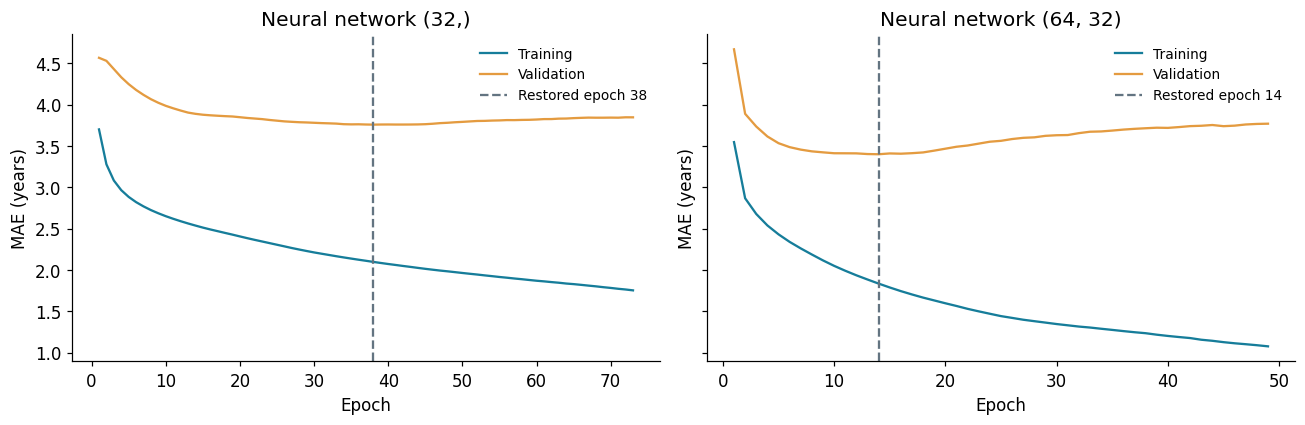

In [9]:
def scores(actual, predicted):
    return {'MAE':mean_absolute_error(actual,predicted),
            'RMSE':np.sqrt(mean_squared_error(actual,predicted)),
            'R2':r2_score(actual,predicted)}
validation_rows = []
rf_runs = []
with threadpool_limits(limits=1):
    for depth in [8, None]:
        model = RandomForestRegressor(n_estimators=200,max_depth=depth,
            min_samples_leaf=4,max_features=.8,random_state=SEED,n_jobs=1)
        model.fit(X_train,y_train)
        result = scores(y_val,model.predict(X_val))
        label = f'Random forest (depth={depth})'
        validation_rows.append({'Configuration':label,**result})
        rf_runs.append((result['MAE'],model,label))
    y_mean, y_sd = y_train.mean(), y_train.std()
    yt = (y_train-y_mean)/y_sd
    nn_runs = []
    for architecture in [(32,), (64,32)]:
        model = MLPRegressor(hidden_layer_sizes=architecture, activation='relu',
            solver='adam',alpha=.01,batch_size=64,learning_rate_init=.001,
            random_state=SEED,shuffle=True)
        history = []
        best_mae, best_model, best_epoch, stale = np.inf, None, 0, 0
        for epoch in range(1,501):
            model.partial_fit(Xs_train,yt)
            train_pred = model.predict(Xs_train)*y_sd+y_mean
            val_pred = model.predict(Xs_val)*y_sd+y_mean
            mae = mean_absolute_error(y_val,val_pred)
            history.append((epoch,mean_absolute_error(y_train,train_pred),mae))
            if mae < best_mae-.001:
                best_mae, best_model, best_epoch, stale = mae, copy.deepcopy(model), epoch, 0
            else:
                stale += 1
            if stale >= 35:
                break
        label = f'Neural network {architecture}'
        result = scores(y_val,best_model.predict(Xs_val)*y_sd+y_mean)
        validation_rows.append({'Configuration':label,**result})
        nn_runs.append((result['MAE'],best_model,label,history,best_epoch))
        print(f'{label}: best epoch {best_epoch}, validation MAE {result["MAE"]:.3f}')
rf_mae, rf_model, rf_label = min(rf_runs,key=lambda r:r[0])
nn_mae, nn_model, nn_label, nn_history, nn_epoch = min(nn_runs,key=lambda r:r[0])
validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(3))
validation_results.to_csv('Project2_Validation_Results.csv',index=False)

fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,(_,_,label,history,best_epoch) in zip(axes,nn_runs):
    curve=np.array(history)
    ax.plot(curve[:,0],curve[:,1],label='Training',color='#167d9a')
    ax.plot(curve[:,0],curve[:,2],label='Validation',color='#e49b40')
    ax.axvline(best_epoch,color='#637481',linestyle='--',label=f'Restored epoch {best_epoch}')
    ax.set(xlabel='Epoch',ylabel='MAE (years)',title=label)
    ax.legend(frameon=False,fontsize=9)
fig.tight_layout()
savefig('04_neural_network_learning.png')

### Model selection

The validation MAE of the two-layer network was lowest (**3.40 years**) and at epoch **14**; whereas the validation MAE of the one-layer network was lowest (**3.76 years**)and at epoch **38**. Training error continues to decrease after these epochs, but validation error either remains constant or increases. This indicates that overfitting may be occurring. In order to do the best job at limiting the effects of overfitting, we can restore the weights from previous epochs. The forest without a maximum-depth limit performed slightly better than the depth-8 forest based on validation data (**3.58 vs. 3.63 years MAE**), and therefore will be used in the test comparison.


## 6. Test results

Both models are evaluated on the same **603 observations from 39 countries and territories excluded from training**. MAE is the main metric whereas RMSE gives more weight to large errors, and R² measures improvement in squared error over the test-set mean. Lower MAE/RMSE and higher R² are better.


,Model,MAE,RMSE,R2
0,Training mean baseline,7.232,9.039,-0.001
1,Random forest,3.125,4.688,0.731
2,Neural network,3.722,6.076,0.548


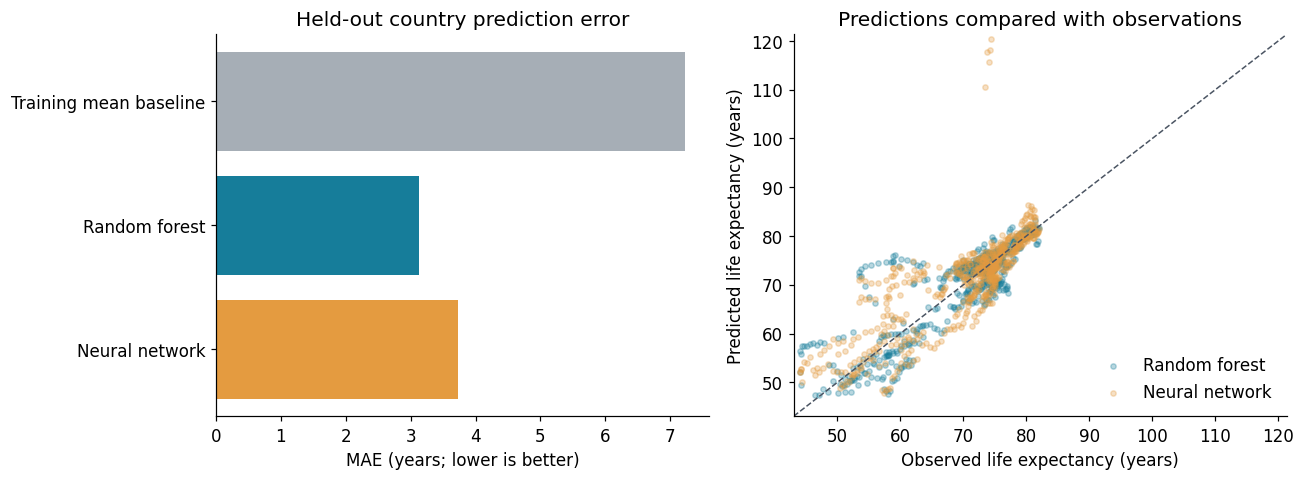

,mean,count
Country,,
Nauru,13.98,5
Belize,13.12,18
South Africa,12.85,18
Tuvalu,9.96,5
Central African Republic,8.16,16
Gabon,8.13,17
Haiti,6.90,16
Sao Tome and Principe,6.55,17
Vietnam,5.09,17


In [10]:
predictions = {'Training mean baseline':np.full(len(y_test), y_train.mean()),
               'Random forest':rf_model.predict(X_test),
               'Neural network':nn_model.predict(Xs_test)*y_sd+y_mean}
test_results=pd.DataFrame([{'Model':name,**scores(y_test,pred)}
                           for name,pred in predictions.items()])
display(test_results.round(3))
test_results.to_csv('Project2_Test_Results.csv',index=False)
prediction_table=test[['Country','Year','Life Expectancy']].copy()
for name,pred in predictions.items():prediction_table[name]=pred
prediction_table.to_csv('Project2_Test_Predictions.csv',index=False)

fig, axes=plt.subplots(1,2,figsize=(12,4.5))
colors=['#a6aeb6','#167d9a','#e49b40']
axes[0].barh(test_results.Model,test_results.MAE,color=colors)
axes[0].invert_yaxis()
axes[0].set(xlabel='MAE (years; lower is better)',title='Held-out country prediction error')
for name,color in zip(['Random forest','Neural network'],colors[1:]):
    axes[1].scatter(y_test,predictions[name],s=12,alpha=.3,label=name,color=color)
lims=[min(y_test.min(),min(p.min() for p in predictions.values()))-1,
      max(y_test.max(),max(p.max() for p in predictions.values()))+1]
axes[1].plot(lims,lims,color='#4b5563',linestyle='--',lw=1)
axes[1].set(xlabel='Observed life expectancy (years)',ylabel='Predicted life expectancy (years)',
            title='Predictions compared with observations',xlim=lims,ylim=lims)
axes[1].legend(frameon=False)
fig.tight_layout()
savefig('05_test_model_comparison.png')

selected_name = 'Random forest' if rf_mae <= nn_mae else 'Neural network'
selected_pred = predictions[selected_name]
errors = prediction_table[['Country','Year','Life Expectancy']].copy()
errors['Absolute error']=np.abs(y_test-selected_pred)
display(errors.groupby('Country')['Absolute error'].agg(['mean','count']).sort_values('mean',ascending=False).head(10).round(2))

### Important predictors and errors

The validation permutation importance measures how much of the forest's Mean Absolute Error (MAE) will/can increase after shuffling a predictor. Sanitation, GDP, and drinking water will be the largest contributors. Predictors that are correlated might have shared information and therefore, importance does not represent a causal effect. The residual plot displays the neural network chosen through validation. Positive values indicate overprediction.



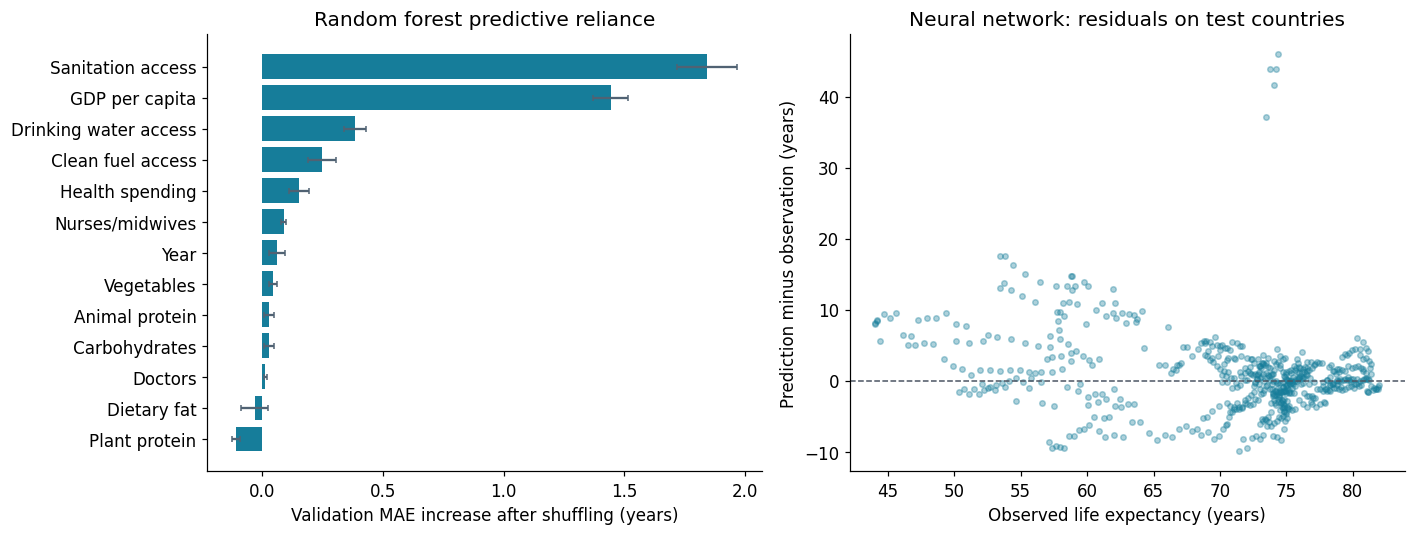

,Feature,MAE increase,SD
3,Basic Sanization Services Total,1.843,0.124
0,GDP per Capita,1.444,0.073
2,Basic Drinking Water Services,0.384,0.048
4,Clean Fuel and Technology,0.248,0.058
1,Government Expenditure Health,0.153,0.042
6,Nurses and Midwifes,0.089,0.010
12,Year,0.061,0.032
7,Vegetable Consumption,0.045,0.017
8,Diet Calories Animal Protein,0.028,0.021
11,Diet Calories Carbohydrates,0.027,0.020


In [11]:
with threadpool_limits(limits=1):
    importance=permutation_importance(rf_model,X_val,y_val,scoring='neg_mean_absolute_error',
                                      n_repeats=10,random_state=SEED,n_jobs=1)
importance_df=pd.DataFrame({'Feature':model_features,'MAE increase':importance.importances_mean,
                            'SD':importance.importances_std}).sort_values('MAE increase')
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].barh([short_names[c] for c in importance_df.Feature],importance_df['MAE increase'],color='#167d9a',
             xerr=importance_df.SD,error_kw={'ecolor':'#506273','capsize':2})
axes[0].set(xlabel='Validation MAE increase after shuffling (years)',title='Random forest predictive reliance')
axes[1].scatter(y_test,selected_pred-y_test,s=13,alpha=.35,color='#167d9a')
axes[1].axhline(0,color='#4b5563',linestyle='--',lw=1)
axes[1].set(xlabel='Observed life expectancy (years)',ylabel='Prediction minus observation (years)',
            title=f'{selected_name}: residuals on test countries')
fig.tight_layout()
savefig('06_importance_and_residuals.png')
display(importance_df.sort_values('MAE increase',ascending=False).round(3))

### A closer look at Belize
The neural network had particularly large errors in Belize during 2013-2017. Nurse/midwife values were 1,853 per 10,000 residents, as compared to a maximum of 201.6 in the training set. The unusual inputs had synchronized with predicted life expectancy values over 110 years, while the forest stayed much closer to the observed life expectancy values. I don't know the reason for the extreme staffing records. This is a strong example that shows how sensitive a model can be to inputs that are outside of its training range. This was investigated after the model was evaluated on test data, the observations and their related errors are still included in all reported scores.

,Training minimum,Training maximum,Belize maximum
Doctors,0.13,82.95,11.45
Nurses and Midwifes,0.23,201.60,1853.00
Government Expenditure Health,0.52,38.90,3.88


Belize staffing values exceed the training range. The dictionary specifies per 10,000 residents; the cause of the extreme records remains unverified.


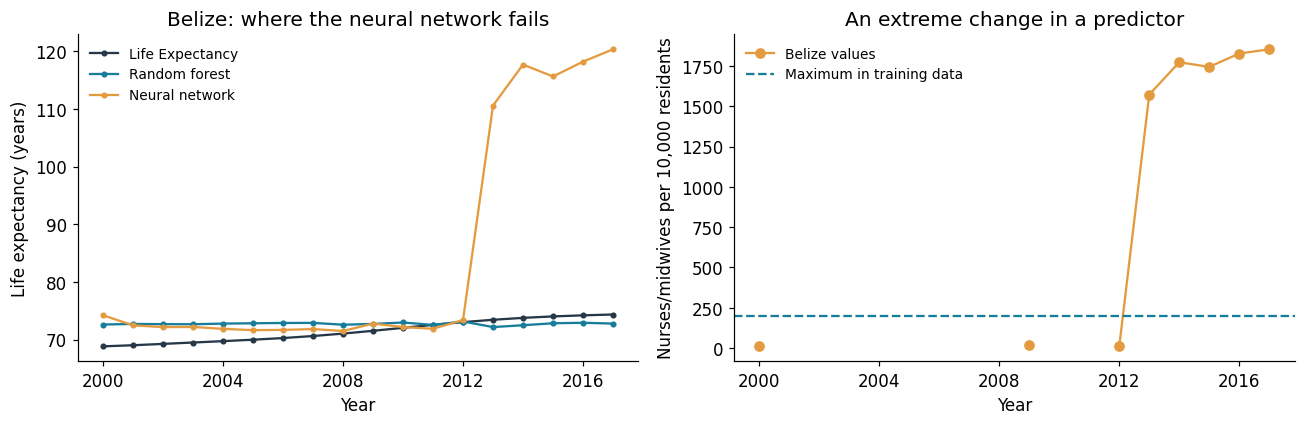

In [12]:
belize = test.loc[test.Country.eq('Belize')].sort_values('Year')
case = prediction_table.loc[prediction_table.Country.eq('Belize')].sort_values('Year')
case_columns=['Doctors','Nurses and Midwifes','Government Expenditure Health']
range_audit=pd.DataFrame({'Training minimum':train[case_columns].min(),
    'Training maximum':train[case_columns].max(),
    'Belize maximum':belize[case_columns].max()})
display(range_audit.round(2))
print('Belize staffing values exceed the training range. The dictionary specifies per 10,000 residents; the cause of the extreme records remains unverified.')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,color in [('Life Expectancy','#263748'),('Random forest','#167d9a'),('Neural network','#e49b40')]:
    axes[0].plot(case.Year,case[name],marker='o',markersize=3,label=name,color=color)
axes[0].set(xlabel='Year',ylabel='Life expectancy (years)',title='Belize: where the neural network fails')
axes[0].legend(frameon=False,fontsize=9)
axes[1].plot(belize.Year,belize['Nurses and Midwifes'],marker='o',color='#e49b40',label='Belize values')
axes[1].axhline(train['Nurses and Midwifes'].max(),linestyle='--',color='#167d9a',label='Maximum in training data')
axes[1].set(xlabel='Year',ylabel='Nurses/midwives per 10,000 residents',title='An extreme change in a predictor')
axes[1].legend(frameon=False,fontsize=9)
for ax in axes:ax.xaxis.set_major_locator(MaxNLocator(integer=True,nbins=6))
fig.tight_layout()
savefig('08_belize_error_case.png')

## 7. Conclusions and limitations

The random forest model has a test **Mean Absolute Error (MAE) of 3.12 years** and an **R-squared value of 0.731**. The neural network model has a **MAE of 3.72 years** and an **R-squared value of 0.548**. Both models perform better than the mean baseline which had a **MAE of 7.23 years**.

While the neural network model has the lowest validation MAE, we can see that the random forest model performs better on the test countries. This clearly indicates that just because a model is more complicated doesn't guarantee it will perform better in general. Additionally, due to having a lower test error and less extreme predictions, the random forest model may be a reasonable starting point for benchmarking. However, a single split does not provide a universal answer as to which model is best. The predictors used in this study provide valuable information regarding longevity and clustering identified distinct economic and service-access profiles.

However: 
- Missing data filtering appeared to eliminate countries/years with few measurements; median imputation could potentially hide differences. 
- The large number of missing staff records and poor documentation from some of the upstream sources decrease confidence in some of the input. 
- Countries have multiple observations and thus model performance will depend on how the countries are split/seed used for training. 
- These are historical country-level predictions, not future forecasts, individual lifespan estimates, or causal effects. Future research should investigate suspicious measurements and test models using multiple country splits before using them in practice.


## 8. References and reproducibility

- Roca, M. (2025). Global Health, Nutrition, Mortality, Economic Data (Version 1). Kaggle. Dataset and dictionary: https://www.kaggle.com/datasets/miguelroca/global-health-nutrition-mortality-economic-data
- Scikit-learn documentation: https://scikit-learn.org/stable/modules/classes.html

- OpenAI. (2026). ChatGPT [Large language model]. https://chatgpt.com/
ChatGPT was used as a reference for Python syntax, debugging, and minor programming assistance during the development of this project.